# Olist Ecommerce in SQL · From Raw Files to a Seller Watch List

The SQL layer of the Olist project. Seven plain `.sql` files in the `sql` folder turn the eight raw Kaggle files into clean analysis tables
and answer the questions behind the Power BI dashboard and the Python notebooks:

| File | What it does | SQL techniques |
|---|---|---|
| `01 raw tables.sql` | One table per Kaggle file | DDL, primary keys |
| `02 clean orders.sql` | Delivered orders with lateness, revenue, category and the latest review | CTEs, `ROW_NUMBER`, joins, date arithmetic, `CASE` |
| `03 kpis and trends.sql` | Monthly KPIs and month-on-month growth, KPIs by region | `LAG`, window totals, `NULLIF` |
| `04 cohort retention.sql` | Monthly cohorts and the 180-day repeat rate | cohort tables, month offsets, conditional aggregation |
| `05 rfm segments.sql` | Recency, Frequency, Monetary scores and segments | `NTILE`, `CROSS JOIN`, `CASE` rules |
| `06 late delivery impact.sql` | Ratings by delivery timing, the late-delivery funnel, worst routes | bucketing, `FILTER`, `RANK`, `HAVING` |
| `07 seller scorecard.sql` | Seller KPIs, rank within state, percentile, watch list | `PARTITION BY`, `PERCENT_RANK`, `COUNT() OVER` |

**Two engines, same SQL.** Every file runs unchanged on **PostgreSQL** (e.g. in SQL Shell / psql with `\i`) and on **DuckDB**, an in-process database that needs no server.
This notebook uses DuckDB by default so anyone can reproduce it. Set `ENGINE = "postgres"` to run everything on a local PostgreSQL instead.

### Key Findings
* **The SQL reproduces the dashboard exactly:** 96,203 delivered orders, 6.8% late, 4.29★ on time against 2.27★ late, on both PostgreSQL and DuckDB.
* **Late orders are 6.8% of deliveries but 32.6% of all 1–2★ reviews.** 61% of late orders end in a low review, against 9% of on-time orders. The rating falls from 4.3★ to 2.1★ once a parcel is 4–7 days late.
* **The North-East is the problem region:** late 12.8% of the time (twice the South-East), freight is 44% of the item price, and delivery takes 20 days on average. SP → RJ is the largest single late route (8,141 orders, 14% late).
* **Olist is an acquisition business:** only 3.0% of customers ever order twice, and no monthly cohort brings back more than 0.7% of its customers in any later month.
* **30 sellers (4% of orders) cause 10% of late deliveries.** They are late at least twice as often as the platform and form a concrete watch list.

In [1]:
# ---- settings ------------------------------------------------------------------------------------
ENGINE = "postgres" 
PG = dict(host="localhost", port=5432, user="postgres", dbname="olist")   # used only when ENGINE = "postgres"
RELOAD = False             # True = reload the raw files even if the tables already exist

# ---- where things live ---------------------------------------------------------------------------
import os, sys
from pathlib import Path

CODE_OVERRIDE = r""        # optional: the folder that contains olistsql.py

def find_module(name):
    if CODE_OVERRIDE:
        hits = sorted(Path(CODE_OVERRIDE).glob(name + "*.py"))
        if hits:
            return hits[0]
    for p in [Path.cwd(), *Path.cwd().parents]:
        hits = sorted(p.glob(name + "*.py"))
        if hits:
            return hits[0]
    home = Path.home()
    for root in [home / "OneDrive" / "Documents", home / "Documents", home / "Downloads", home / "Desktop", home / "OneDrive"]:
        if root.exists():
            try:
                hits = [h for h in root.rglob(name + "*.py") if ".ipynb_checkpoints" not in h.parts]
            except OSError:
                continue
            if hits:
                return sorted(hits, key=lambda f: (len(f.parts), f.name))[0]
    return None

MODULE_FILE = find_module("olistsql")
if MODULE_FILE is None:
    raise FileNotFoundError("olistsql.py not found. Put it in the same folder as this notebook, or paste that folder into CODE_OVERRIDE.")
CODE = MODULE_FILE.parent
os.chdir(CODE)
sys.path.insert(0, str(CODE))
import olistsql as osql
from olisttools import NAVY, BLUE, AMBER, GREEN, RED, PURPLE, CYAN, INK, MUTED, LINE, BLUE_L, RED_L, style_charts

DATA = CODE / "data"
IMAGES = CODE / "images"
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
style_charts()
pd.set_option("display.max_columns", 20)

# ---- connect -------------------------------------------------------------------------------------
if ENGINE == "postgres":
    from getpass import getpass
    con = osql.connect("postgres", password=getpass("PostgreSQL password: "), **PG)   # the password is never saved
else:
    con = osql.connect("duckdb")
print("Engine:", ENGINE, "| Code:", CODE.name, "| Data:", DATA.name)

def show_sql(file):
    # print the SQL so the notebook reads like a report
    text = (CODE / "sql" / f"{file}.sql").read_text(encoding="utf-8")
    text = "\n".join(l for l in text.splitlines() if not l.startswith("\\"))
    display(Markdown(f"<details><summary><b>Show the SQL · {file}.sql</b></summary>\n\n```sql\n{text}\n```\n</details>"))

def run(file):
    show_sql(file)
    return osql.run_file(con, CODE / "sql" / f"{file}.sql")

PostgreSQL password: ········
Engine: postgres | Code: Olist Ecommerce | Data: data


## 1 · Load the Raw Files

The eight Kaggle files (compressed `.csv.gz` in the `data` folder; the original `.csv` files work too) are loaded into `raw_*` tables exactly as they are.
On PostgreSQL the loader uses `COPY`, the fastest bulk-load path.

In [2]:
if RELOAD or not osql.table_exists(con, "raw_orders"):
    osql.load_raw(con, DATA)
counts = pd.concat([con.query(f"SELECT '{t}' AS table_name, COUNT(*) AS row_count FROM {t}") for t in
                    ["raw_orders", "raw_customers", "raw_order_items", "raw_order_payments", "raw_order_reviews",
                     "raw_products", "raw_sellers", "raw_category_translation"]], ignore_index=True)
counts.style.hide(axis="index").format({"row_count": "{:,.0f}"})

raw_customers                99,441 rows  <- olist customers dataset.csv.gz
raw_order_items             112,650 rows  <- olist order items dataset.csv.gz
raw_order_payments          103,886 rows  <- olist order payments dataset.csv.gz
raw_order_reviews            99,224 rows  <- olist order reviews dataset.csv.gz
raw_orders                   99,441 rows  <- olist orders dataset.csv.gz
raw_products                 32,951 rows  <- olist products dataset.csv.gz
raw_sellers                   3,095 rows  <- olist sellers dataset.csv.gz
raw_category_translation         71 rows  <- product category name translation.csv.gz


table_name,row_count
raw_orders,"99,441"
raw_customers,"99,441"
raw_order_items,"112,650"
raw_order_payments,"103,886"
raw_order_reviews,"99,224"
raw_products,"32,951"
raw_sellers,"3,095"
raw_category_translation,71


## 2 · Clean Analysis Tables

`fact_items` adds the English category and the seller's state to every item. `fact_orders` keeps one row per **delivered** order (Jan 2017 – Aug 2018),
with the promised and actual delivery days, whether it was late, revenue, the first item's category and seller, and the **latest review** (`ROW_NUMBER` per order).
The last query checks the result against the Power BI dashboard.

In [3]:
r = run("02 clean orders")
r["reconciliation"].style.hide(axis="index").format({"delivered_orders": "{:,.0f}", "customers": "{:,.0f}", "revenue_brl": "{:,.0f}",
                                                    "late_pct": "{:.1f}%", "avg_review_on_time": "{:.2f}", "avg_review_late": "{:.2f}"})

<details><summary><b>Show the SQL · 02 clean orders.sql</b></summary>

```sql
-- =====================================================================================
-- 02 · Clean analysis tables
-- Same rules as the Power BI model and the Python notebook:
--   * purchases from 1 Jan 2017 to 31 Aug 2018, delivered orders only
--   * late = delivered (date) after the estimated delivery date
--   * revenue = item price (freight excluded), customers = customer_unique_id
--   * one review per order: the latest answer
-- =====================================================================================

-- Items with English category and seller state
DROP TABLE IF EXISTS fact_items;
CREATE TABLE fact_items AS
SELECT
    i.order_id,
    i.order_item_id,
    i.product_id,
    i.seller_id,
    s.seller_state,
    COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
    i.price,
    i.freight_value,
    p.product_weight_g,
    p.product_length_cm * p.product_height_cm * p.product_width_cm AS product_volume_cm3
FROM raw_order_items AS i
LEFT JOIN raw_products AS p ON p.product_id = i.product_id
LEFT JOIN raw_category_translation AS t ON t.product_category_name = p.product_category_name
LEFT JOIN raw_sellers AS s ON s.seller_id = i.seller_id;

ANALYZE fact_items;

-- One row per delivered order
DROP TABLE IF EXISTS fact_orders;
CREATE TABLE fact_orders AS
WITH latest_review AS (
    SELECT order_id, review_score, review_creation_date, review_comment_message,
           ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC, review_id) AS rn
    FROM raw_order_reviews
),
item_totals AS (
    SELECT order_id,
           SUM(price)                AS revenue,
           SUM(freight_value)        AS freight,
           COUNT(*)                  AS items,
           COUNT(DISTINCT seller_id) AS sellers,
           SUM(product_weight_g)     AS weight_g
    FROM fact_items
    GROUP BY order_id
),
first_item AS (          -- category and seller of the first item, as in the notebook
    SELECT order_id, category, seller_id, seller_state,
           ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY order_item_id) AS rn
    FROM fact_items
)
SELECT
    o.order_id,
    c.customer_unique_id,
    c.customer_state,
    CASE
        WHEN c.customer_state IN ('AC','AP','AM','PA','RO','RR','TO') THEN 'North'
        WHEN c.customer_state IN ('AL','BA','CE','MA','PB','PE','PI','RN','SE') THEN 'Northeast'
        WHEN c.customer_state IN ('DF','GO','MT','MS') THEN 'Center-West'
        WHEN c.customer_state IN ('ES','MG','RJ','SP') THEN 'Southeast'
        WHEN c.customer_state IN ('PR','RS','SC') THEN 'South'
    END                                                              AS region,
    o.order_purchase_timestamp                                       AS purchased_at,
    CAST(o.order_purchase_timestamp AS DATE)                         AS purchase_date,
    CAST(DATE_TRUNC('month', o.order_purchase_timestamp) AS DATE)    AS purchase_month,
    CAST(o.order_delivered_customer_date AS DATE)                    AS delivered_date,
    CAST(o.order_estimated_delivery_date AS DATE)                    AS estimated_date,
    CAST(o.order_estimated_delivery_date AS DATE) - CAST(o.order_purchase_timestamp AS DATE)  AS promised_days,
    CAST(o.order_delivered_customer_date AS DATE) - CAST(o.order_purchase_timestamp AS DATE)  AS delivery_days,
    CAST(o.order_delivered_customer_date AS DATE) - CAST(o.order_estimated_delivery_date AS DATE) AS days_late,
    CAST(o.order_delivered_customer_date AS DATE) > CAST(o.order_estimated_delivery_date AS DATE) AS is_late,
    it.revenue,
    it.freight,
    it.items,
    it.sellers,
    it.weight_g,
    fi.category,
    fi.seller_id,
    fi.seller_state,
    fi.seller_state = c.customer_state                               AS same_state,
    r.review_score,
    CAST(r.review_creation_date AS DATE) < CAST(o.order_delivered_customer_date AS DATE) AS review_before_arrival
FROM raw_orders AS o
JOIN raw_customers AS c ON c.customer_id = o.customer_id
LEFT JOIN item_totals AS it ON it.order_id = o.order_id
LEFT JOIN first_item  AS fi ON fi.order_id = o.order_id AND fi.rn = 1
LEFT JOIN latest_review AS r ON r.order_id = o.order_id AND r.rn = 1
WHERE o.order_purchase_timestamp >= TIMESTAMP '2017-01-01'
  AND o.order_purchase_timestamp <  TIMESTAMP '2018-09-01'
  AND o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL;

ANALYZE fact_orders;

-- Check against the dashboard: 96,203 delivered orders, 6.8% late, 4.3★ on time vs 2.3★ late
-- result: reconciliation
SELECT
    COUNT(*)                                                                 AS delivered_orders,
    COUNT(DISTINCT customer_unique_id)                                       AS customers,
    ROUND(CAST(SUM(revenue) AS NUMERIC(18,6)), 0)                                  AS revenue_brl,
    ROUND(CAST(100.0 * AVG(CASE WHEN is_late THEN 1 ELSE 0 END) AS NUMERIC(18,6)), 1) AS late_pct,
    ROUND(CAST(AVG(review_score) FILTER (WHERE NOT is_late) AS NUMERIC(18,6)), 2)  AS avg_review_on_time,
    ROUND(CAST(AVG(review_score) FILTER (WHERE is_late) AS NUMERIC(18,6)), 2)      AS avg_review_late
FROM fact_orders;
```
</details>

delivered_orders,customers,revenue_brl,late_pct,avg_review_on_time,avg_review_late
"96,203","93,096","13,179,778",6.8%,4.29,2.27


**Reading the check:** 96,203 delivered orders from 93,096 customers, R$13.18M of item revenue, 6.8% late, 4.29★ on time against 2.27★ late. These are the same numbers as the Power BI dashboard and the Python notebook, so the three layers of the project describe the same data.

## 3 · KPIs and Trends

<details><summary><b>Show the SQL · 03 kpis and trends.sql</b></summary>

```sql
-- =====================================================================================
-- 03 · KPIs and trends
-- Monthly volume, revenue growth (LAG), lateness and ratings; the same KPIs by region.
-- =====================================================================================

-- result: monthly trend
WITH monthly AS (
    SELECT
        purchase_month,
        COUNT(*)                                              AS orders,
        SUM(revenue)                                          AS revenue,
        AVG(CASE WHEN is_late THEN 1.0 ELSE 0.0 END)          AS late_rate,
        AVG(CAST(review_score AS DOUBLE PRECISION))           AS avg_review,
        AVG(CASE WHEN review_score <= 2 THEN 1.0 ELSE 0.0 END) AS low_review_rate
    FROM fact_orders
    GROUP BY purchase_month
)
SELECT
    purchase_month,
    orders,
    ROUND(CAST(revenue AS NUMERIC(18,6)), 0)                                               AS revenue_brl,
    ROUND(CAST(100.0 * (revenue / LAG(revenue) OVER (ORDER BY purchase_month) - 1) AS NUMERIC(18,6)), 1) AS revenue_mom_pct,
    ROUND(CAST(100.0 * late_rate AS NUMERIC(18,6)), 1)                                     AS late_pct,
    ROUND(CAST(avg_review AS NUMERIC(18,6)), 2)                                            AS avg_review,
    ROUND(CAST(100.0 * low_review_rate AS NUMERIC(18,6)), 1)                               AS low_review_pct
FROM monthly
ORDER BY purchase_month;

-- result: kpis by region
SELECT
    region,
    COUNT(*)                                                                   AS orders,
    ROUND(CAST(100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS NUMERIC(18,6)), 1)        AS share_of_orders_pct,
    ROUND(CAST(AVG(revenue) AS NUMERIC(18,6)), 1)                                    AS avg_order_brl,
    ROUND(CAST(100.0 * AVG(freight / NULLIF(revenue, 0)) AS NUMERIC(18,6)), 1)       AS freight_pct_of_price,
    ROUND(CAST(AVG(CAST(delivery_days AS DOUBLE PRECISION)) AS NUMERIC(18,6)), 1)    AS avg_delivery_days,
    ROUND(CAST(100.0 * AVG(CASE WHEN is_late THEN 1.0 ELSE 0.0 END) AS NUMERIC(18,6)), 1) AS late_pct,
    ROUND(CAST(AVG(CAST(review_score AS DOUBLE PRECISION)) AS NUMERIC(18,6)), 2)    AS avg_review
FROM fact_orders
GROUP BY region
ORDER BY late_pct DESC;
```
</details>

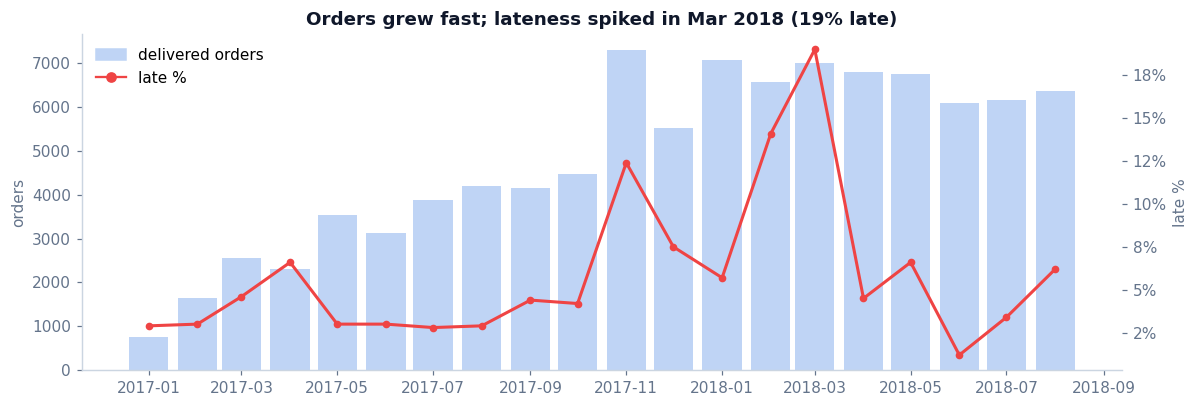

region,orders,share_of_orders_pct,avg_order_brl,freight_pct_of_price,avg_delivery_days,late_pct,avg_review
Northeast,"9,015",9.4%,R$ 166,44%,19.9,12.8%,3.97
North,"1,791",1.9%,R$ 182,49%,22.5,8.6%,4.03
Center-West,"5,610",5.8%,R$ 151,34%,14.9,6.5%,4.13
Southeast,"66,020",68.6%,R$ 131,28%,10.7,6.1%,4.18
South,"13,767",14.3%,R$ 138,34%,14.0,5.9%,4.19


In [4]:
r = run("03 kpis and trends")
m = r["monthly trend"].copy()
m["purchase_month"] = pd.to_datetime(m.purchase_month)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(m.purchase_month, m.orders, width=25, color=BLUE_L, label="delivered orders")
ax.set_ylabel("orders")
ax2 = ax.twinx()
ax2.plot(m.purchase_month, m.late_pct, color=RED, lw=2, marker="o", ms=4, label="late %")
ax2.set_ylabel("late %"); ax2.spines["top"].set_visible(False)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE_L), plt.Line2D([], [], color=RED, marker="o")],
          labels=["delivered orders", "late %"], frameon=False, loc="upper left")
peak = m.loc[m.late_pct.idxmax()]
ax.set_title(f"Orders grew fast; lateness spiked in {peak.purchase_month:%b %Y} ({peak.late_pct:.0f}% late)")
plt.tight_layout(); save(fig, "sql monthly trend"); plt.show()
r["kpis by region"].style.hide(axis="index").format({"orders": "{:,.0f}", "share_of_orders_pct": "{:.1f}%", "avg_order_brl": "R$ {:.0f}",
    "freight_pct_of_price": "{:.0f}%", "avg_delivery_days": "{:.1f}", "late_pct": "{:.1f}%", "avg_review": "{:.2f}"})

**Reading the Trends**
* Orders grew almost **10×** from Jan 2017 (750) to Nov 2017 (7,288, Black Friday) and then levelled off at 6–7K a month.
* **Lateness comes in spikes, not a slow drift:** 12% in Nov 2017 (Black Friday), then 14% in Feb 2018 and **19% in Mar 2018**, against 3–5% in a normal month. Capacity planning around peaks matters more than average performance.
* **By region, the North-East stands out:** 12.8% late (twice the South-East's 6.1%), 19.9 delivery days against 10.7, freight equal to 44% of the item price, and the lowest rating (3.97★).

## 4 · Cohort retention

<details><summary><b>Show the SQL · 04 cohort retention.sql</b></summary>

```sql
-- =====================================================================================
-- 04 · Cohort retention
-- Customers grouped by the month of their first delivered order; the share who order again
-- 1, 2, ... 12 months later. Then the 180-day repeat rate used in the notebook (3.0%).
-- =====================================================================================

DROP TABLE IF EXISTS customer_months;
CREATE TABLE customer_months AS
WITH firsts AS (
    SELECT customer_unique_id, MIN(purchase_month) AS cohort_month
    FROM fact_orders
    GROUP BY customer_unique_id
)
SELECT DISTINCT
    o.customer_unique_id,
    f.cohort_month,
    o.purchase_month,
    CAST((EXTRACT(YEAR FROM o.purchase_month) - EXTRACT(YEAR FROM f.cohort_month)) * 12
         + EXTRACT(MONTH FROM o.purchase_month) - EXTRACT(MONTH FROM f.cohort_month) AS INTEGER) AS month_number
FROM fact_orders AS o
JOIN firsts AS f ON f.customer_unique_id = o.customer_unique_id;

-- result: cohort retention
WITH cohort_size AS (
    SELECT cohort_month, COUNT(DISTINCT customer_unique_id) AS customers
    FROM customer_months
    WHERE month_number = 0
    GROUP BY cohort_month
),
active AS (
    SELECT cohort_month, month_number, COUNT(DISTINCT customer_unique_id) AS active_customers
    FROM customer_months
    WHERE month_number BETWEEN 1 AND 12
    GROUP BY cohort_month, month_number
)
SELECT
    c.cohort_month,
    c.customers,
    a.month_number,
    a.active_customers,
    ROUND(CAST(100.0 * a.active_customers / c.customers AS NUMERIC(18,6)), 2) AS retention_pct
FROM cohort_size AS c
JOIN active AS a ON a.cohort_month = c.cohort_month
WHERE c.cohort_month <= DATE '2018-02-01'          -- cohorts with at least 6 months of follow-up
ORDER BY c.cohort_month, a.month_number;

-- result: repeat customers
-- Share of customers with two or more delivered orders (the dashboard's 3.0%).
SELECT
    COUNT(*)                                                                    AS customers,
    SUM(CASE WHEN orders >= 2 THEN 1 ELSE 0 END)                                AS repeat_customers,
    ROUND(CAST(100.0 * AVG(CASE WHEN orders >= 2 THEN 1.0 ELSE 0.0 END) AS NUMERIC(18,6)), 1) AS repeat_customers_pct
FROM (
    SELECT customer_unique_id, COUNT(DISTINCT order_id) AS orders
    FROM fact_orders
    GROUP BY customer_unique_id
) AS per_customer;

-- result: repeat within 180 days
-- Second order on a different day within 180 days, for customers whose first order is before
-- 1 Mar 2018 (so every customer has a full 180-day window before the data ends).
WITH customer_days AS (
    SELECT DISTINCT customer_unique_id, purchase_date
    FROM fact_orders
),
ranked AS (
    SELECT customer_unique_id, purchase_date,
           ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchase_date) AS nth
    FROM customer_days
),
first_two AS (
    SELECT customer_unique_id,
           MAX(CASE WHEN nth = 1 THEN purchase_date END) AS first_date,
           MAX(CASE WHEN nth = 2 THEN purchase_date END) AS second_date
    FROM ranked
    WHERE nth <= 2
    GROUP BY customer_unique_id
)
SELECT
    COUNT(*)                                                                         AS eligible_customers,
    SUM(CASE WHEN second_date - first_date <= 180 THEN 1 ELSE 0 END)                 AS repeat_customers,
    ROUND(CAST(100.0 * AVG(CASE WHEN second_date - first_date <= 180 THEN 1.0 ELSE 0.0 END) AS NUMERIC(18,6)), 1) AS repeat_pct,
    ROUND(CAST(AVG(CAST(second_date - first_date AS DOUBLE PRECISION)) AS NUMERIC(18,6)), 0) AS avg_days_to_second_order
FROM first_two
WHERE first_date < DATE '2018-03-01';
```
</details>

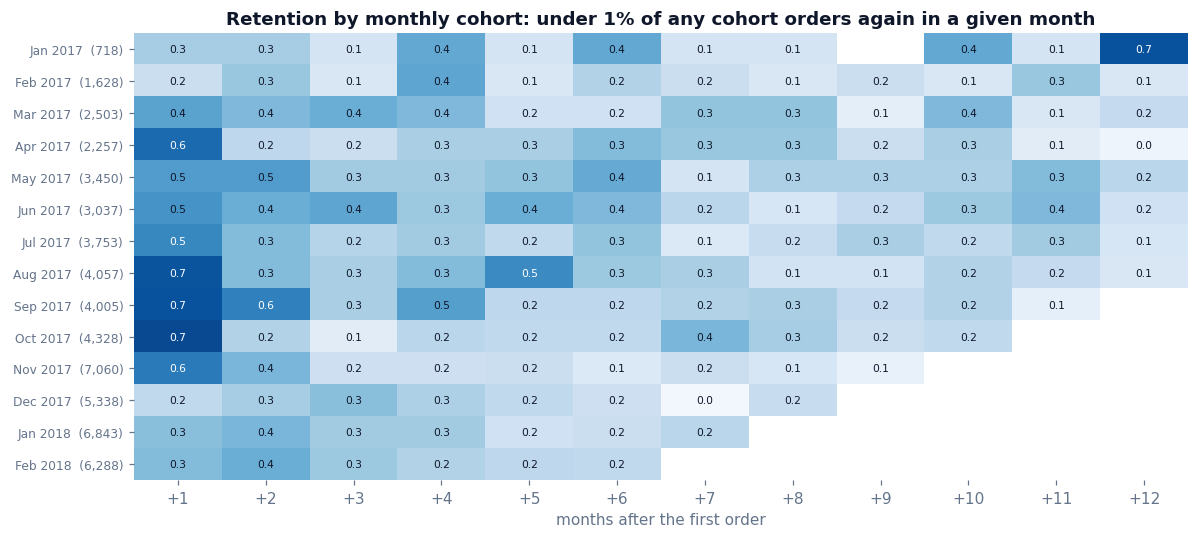

customers,repeat_customers,repeat_customers_pct
"93,096","2,789",3.0%


eligible_customers,repeat_customers,repeat_pct,avg_days_to_second_order
"55,265","1,098",2.0%,134


In [5]:
r = run("04 cohort retention")
c = r["cohort retention"].copy()
c["cohort_month"] = pd.to_datetime(c.cohort_month).dt.strftime("%b %Y")
grid = c.pivot(index="cohort_month", columns="month_number", values="retention_pct")
grid = grid.reindex(c.drop_duplicates("cohort_month").cohort_month)
sizes = c.drop_duplicates("cohort_month").set_index("cohort_month").customers

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=0.8, aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else INK)
ax.set_xticks(range(grid.shape[1])); ax.set_xticklabels([f"+{k}" for k in grid.columns])
ax.set_yticks(range(grid.shape[0])); ax.set_yticklabels([f"{k}  ({sizes[k]:,})" for k in grid.index], fontsize=8)
ax.set_xlabel("months after the first order"); ax.spines[:].set_visible(False)
ax.set_title("Retention by monthly cohort: under 1% of any cohort orders again in a given month")
plt.tight_layout(); save(fig, "sql cohort retention"); plt.show()
display(r["repeat customers"].style.hide(axis="index").format({"customers": "{:,.0f}", "repeat_customers": "{:,.0f}", "repeat_customers_pct": "{:.1f}%"}))
r["repeat within 180 days"].style.hide(axis="index").format({"eligible_customers": "{:,.0f}", "repeat_customers": "{:,.0f}",
                                                            "repeat_pct": "{:.1f}%", "avg_days_to_second_order": "{:.0f}"})

**Reading the cohorts**
* Retention is close to zero everywhere: on average **0.5% of a cohort orders again in its first month**, and 0.2–0.3% in later months. No cohort ever exceeds 0.7%.
* Only **3.0% of all customers ever order twice**, and 2.0% do so within 180 days. When they do come back, it takes **134 days** on average.
* This is the same conclusion as the Python notebook, now in plain SQL: Olist is an **acquisition business**. Retention campaigns have a very small base to work with, so first-order experience matters mainly through reviews, not repeat purchases.

## 5 · RFM Segments

<details><summary><b>Show the SQL · 05 rfm segments.sql</b></summary>

```sql
-- =====================================================================================
-- 05 · RFM segments
-- Recency, Frequency and Monetary value per customer, scored 1–5 with NTILE.
-- Frequency is 1 for about 97% of customers, so segments lean on Recency × Monetary.
-- =====================================================================================

DROP TABLE IF EXISTS customer_rfm;
CREATE TABLE customer_rfm AS
WITH snapshot AS (
    SELECT MAX(purchase_date) + 1 AS as_of FROM fact_orders
),
base AS (
    SELECT
        o.customer_unique_id,
        MIN(s.as_of - o.purchase_date)          AS recency_days,
        COUNT(DISTINCT o.order_id)              AS frequency,
        SUM(o.revenue)                          AS monetary
    FROM fact_orders AS o
    CROSS JOIN snapshot AS s
    GROUP BY o.customer_unique_id
),
scored AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY recency_days DESC, customer_unique_id) AS r_score,   -- 5 = bought most recently
           NTILE(5) OVER (ORDER BY monetary, customer_unique_id) AS m_score,   -- 5 = spent the most
           CASE WHEN frequency >= 3 THEN 5 WHEN frequency = 2 THEN 4 ELSE 1 END AS f_score
    FROM base
)
SELECT *,
       CASE
           WHEN frequency >= 2 AND r_score >= 3 THEN 'Loyal repeaters'
           WHEN frequency >= 2                  THEN 'Lapsed repeaters'
           WHEN r_score >= 4 AND m_score >= 4   THEN 'New big spenders'
           WHEN r_score >= 4                    THEN 'New small spenders'
           WHEN r_score <= 2 AND m_score >= 4   THEN 'Big spenders at risk'
           WHEN r_score <= 2                    THEN 'Hibernating'
           ELSE 'Middle'
       END AS segment
FROM scored;

-- result: rfm segments
SELECT
    segment,
    COUNT(*)                                                                 AS customers,
    ROUND(CAST(100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS NUMERIC(18,6)), 1)      AS share_of_customers_pct,
    ROUND(CAST(100.0 * SUM(monetary) / SUM(SUM(monetary)) OVER () AS NUMERIC(18,6)), 1) AS share_of_revenue_pct,
    ROUND(CAST(AVG(CAST(recency_days AS DOUBLE PRECISION)) AS NUMERIC(18,6)), 0)   AS avg_recency_days,
    ROUND(CAST(AVG(frequency * 1.0) AS NUMERIC(18,6)), 2)                          AS avg_orders,
    ROUND(CAST(AVG(monetary) AS NUMERIC(18,6)), 0)                                 AS avg_spend_brl
FROM customer_rfm
GROUP BY segment
ORDER BY share_of_revenue_pct DESC;
```
</details>

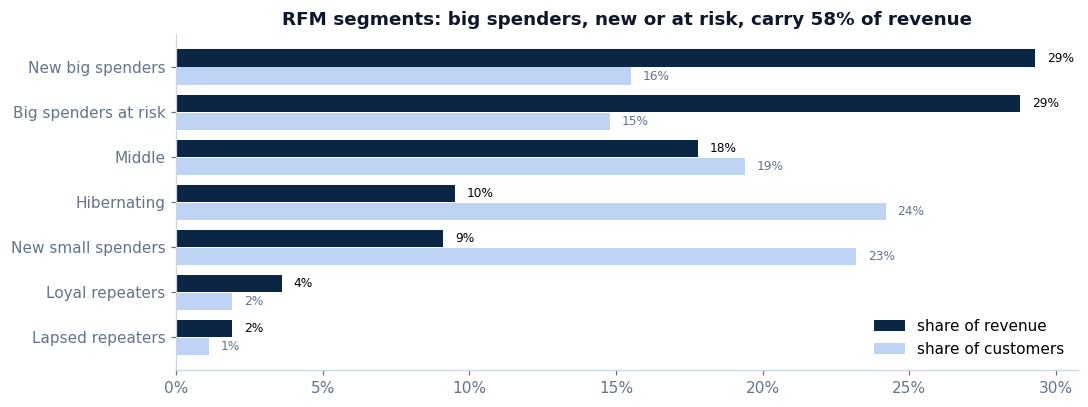

segment,customers,share_of_customers_pct,share_of_revenue_pct,avg_recency_days,avg_orders,avg_spend_brl
New big spenders,"14,438",15.5%,29.3%,92,1.00,R$ 267
Big spenders at risk,"13,744",14.8%,28.8%,392,1.00,R$ 276
Middle,"18,021",19.4%,17.8%,220,1.00,R$ 130
Hibernating,"22,499",24.2%,9.5%,393,1.00,R$ 56
New small spenders,"21,605",23.2%,9.1%,90,1.00,R$ 56
Loyal repeaters,"1,793",1.9%,3.6%,131,2.13,R$ 266
Lapsed repeaters,996,1.1%,1.9%,380,2.08,R$ 250


In [6]:
r = run("05 rfm segments")
s = r["rfm segments"].sort_values("share_of_revenue_pct")
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(s))
ax.barh(y + 0.2, s.share_of_revenue_pct, height=0.38, color=NAVY, label="share of revenue")
ax.barh(y - 0.2, s.share_of_customers_pct, height=0.38, color=BLUE_L, label="share of customers")
for i, (a, b) in enumerate(zip(s.share_of_revenue_pct, s.share_of_customers_pct)):
    ax.text(a + 0.4, i + 0.2, f"{a:.0f}%", va="center", fontsize=8)
    ax.text(b + 0.4, i - 0.2, f"{b:.0f}%", va="center", fontsize=8, color=MUTED)
ax.set_yticks(y); ax.set_yticklabels(s.segment)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
big = s.set_index("segment").loc[["New big spenders", "Big spenders at risk"], "share_of_revenue_pct"].sum()
ax.legend(frameon=False, loc="lower right"); ax.set_title(f"RFM segments: big spenders, new or at risk, carry {big:.0f}% of revenue")
plt.tight_layout(); save(fig, "sql rfm segments"); plt.show()
r["rfm segments"].style.hide(axis="index").format({"customers": "{:,.0f}", "share_of_customers_pct": "{:.1f}%", "share_of_revenue_pct": "{:.1f}%",
    "avg_recency_days": "{:.0f}", "avg_orders": "{:.2f}", "avg_spend_brl": "R$ {:.0f}"})

**Reading the Segments**
* **Two segments carry 58% of revenue:** *New big spenders* (15.5% of customers, 29.3% of revenue) and *Big spenders at risk* (14.8% of customers, 28.8% of revenue, last order about 13 months ago, R$276 average).
* **Repeat customers are tiny:** loyal and lapsed repeaters together are 3.0% of customers and 5.5% of revenue.
* The most valuable win-back list is therefore not "repeaters" but the **13,744 big spenders at risk**: high value, one order, long silence.

## 6 · What a Late Box Costs

<details><summary><b>Show the SQL · 06 late delivery impact.sql</b></summary>

```sql
-- =====================================================================================
-- 06 · What a late box costs
-- Ratings by delivery timing, the late-delivery funnel, and the worst shipping routes.
-- =====================================================================================

-- result: rating by delivery timing
SELECT
    CASE
        WHEN days_late <= -8 THEN '1 - 8+ days early'
        WHEN days_late <= -1 THEN '2 - 1-7 days early'
        WHEN days_late = 0   THEN '3 - on the day'
        WHEN days_late <= 3  THEN '4 - 1-3 days late'
        WHEN days_late <= 7  THEN '5 - 4-7 days late'
        WHEN days_late <= 14 THEN '6 - 8-14 days late'
        ELSE                      '7 - 15+ days late'
    END                                                                         AS delivery_timing,
    COUNT(*)                                                                    AS orders,
    ROUND(CAST(100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS NUMERIC(18,6)), 1)         AS share_pct,
    ROUND(CAST(AVG(CAST(review_score AS DOUBLE PRECISION)) AS NUMERIC(18,6)), 2)     AS avg_review,
    ROUND(CAST(100.0 * AVG(CASE WHEN review_score <= 2 THEN 1.0 ELSE 0.0 END) AS NUMERIC(18,6)), 1) AS low_review_pct,
    ROUND(CAST(100.0 * AVG(CASE WHEN review_before_arrival THEN 1.0 ELSE 0.0 END) AS NUMERIC(18,6)), 1) AS reviewed_before_arrival_pct
FROM fact_orders
GROUP BY 1
ORDER BY 1;

-- result: late delivery funnel
-- Of all low (1–2★) reviews, how many sit on late orders? Of late orders, how many end in a low review?
SELECT
    COUNT(*)                                                               AS delivered_orders,
    SUM(CASE WHEN is_late THEN 1 ELSE 0 END)                               AS late_orders,
    SUM(CASE WHEN is_late AND review_score <= 2 THEN 1 ELSE 0 END)         AS late_and_low_review,
    SUM(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END)                     AS all_low_reviews,
    ROUND(CAST(100.0 * SUM(CASE WHEN is_late AND review_score <= 2 THEN 1 ELSE 0 END)
               / NULLIF(SUM(CASE WHEN is_late THEN 1 ELSE 0 END), 0) AS NUMERIC(18,6)), 1)  AS late_to_low_review_pct,
    ROUND(CAST(100.0 * SUM(CASE WHEN NOT is_late AND review_score <= 2 THEN 1 ELSE 0 END)
               / NULLIF(SUM(CASE WHEN NOT is_late THEN 1 ELSE 0 END), 0) AS NUMERIC(18,6)), 1) AS on_time_to_low_review_pct,
    ROUND(CAST(100.0 * SUM(CASE WHEN is_late AND review_score <= 2 THEN 1 ELSE 0 END)
               / NULLIF(SUM(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END), 0) AS NUMERIC(18,6)), 1) AS share_of_low_reviews_on_late_pct
FROM fact_orders;

-- result: worst shipping routes
-- Seller state → customer state, routes with at least 300 orders, ranked by late rate.
WITH routes AS (
    SELECT
        seller_state || ' -> ' || customer_state                         AS route,
        same_state,
        COUNT(*)                                                         AS orders,
        AVG(CASE WHEN is_late THEN 1.0 ELSE 0.0 END)                     AS late_rate,
        AVG(CAST(promised_days AS DOUBLE PRECISION))                     AS avg_promised_days,
        AVG(CAST(delivery_days AS DOUBLE PRECISION))                     AS avg_delivery_days,
        AVG(CAST(review_score AS DOUBLE PRECISION))                      AS avg_review
    FROM fact_orders
    WHERE seller_state IS NOT NULL
    GROUP BY seller_state, customer_state, same_state
    HAVING COUNT(*) >= 300
)
SELECT
    RANK() OVER (ORDER BY late_rate DESC)                   AS rank,
    route,
    orders,
    ROUND(CAST(100.0 * late_rate AS NUMERIC(18,6)), 1)            AS late_pct,
    ROUND(CAST(avg_promised_days AS NUMERIC(18,6)), 1)            AS avg_promised_days,
    ROUND(CAST(avg_delivery_days AS NUMERIC(18,6)), 1)            AS avg_delivery_days,
    ROUND(CAST(avg_review AS NUMERIC(18,6)), 2)                   AS avg_review
FROM routes
ORDER BY late_rate DESC
LIMIT 10;
```
</details>

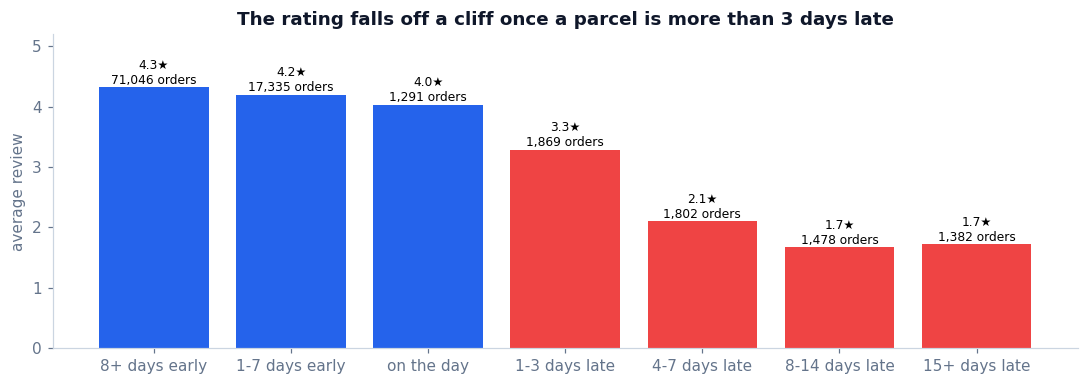

delivered_orders,late_orders,late_and_low_review,all_low_reviews,late_to_low_review_pct,on_time_to_low_review_pct,share_of_low_reviews_on_late_pct
"96,203","6,531","3,981","12,228",61.0%,9.2%,32.6%


rank,route,orders,late_pct,avg_promised_days,avg_delivery_days,avg_review
1,SP -> MA,488,19.1%,31.1,21.9,3.71
2,SP -> PI,328,16.5%,30.7,20.3,3.96
3,SP -> RJ,"8,141",14.2%,27.0,16.2,3.89
4,SP -> CE,966,13.8%,31.9,21.1,3.97
5,SP -> BA,"2,304",12.9%,30.5,19.8,3.87
6,SP -> MS,477,12.4%,26.1,15.9,4.08
7,SP -> ES,"1,460",12.3%,25.2,15.7,4.05
8,PR -> RJ,960,12.2%,30.3,17.2,3.90
9,SP -> PA,678,12.1%,37.2,23.2,3.87
10,SP -> PB,335,10.4%,33.5,20.6,4.04


In [7]:
r = run("06 late delivery impact")
t = r["rating by delivery timing"].copy()
t["label"] = t.delivery_timing.str.split(" - ", n=1).str[1]
fig, ax = plt.subplots(figsize=(10, 3.6))
cols = [BLUE if "early" in l or "on the day" in l else RED for l in t.label]
ax.bar(t.label, t.avg_review, color=cols)
for i, (v, n) in enumerate(zip(t.avg_review, t.orders)):
    ax.text(i, v + 0.06, f"{v:.1f}★\n{n:,} orders", ha="center", fontsize=8)
ax.set_ylim(0, 5.2); ax.set_ylabel("average review")
ax.set_title("The rating falls off a cliff once a parcel is more than 3 days late")
plt.tight_layout(); save(fig, "sql rating by delivery timing"); plt.show()
display(r["late delivery funnel"].style.hide(axis="index").format("{:,.0f}", subset=["delivered_orders", "late_orders", "late_and_low_review", "all_low_reviews"])
        .format("{:.1f}%", subset=["late_to_low_review_pct", "on_time_to_low_review_pct", "share_of_low_reviews_on_late_pct"]))
r["worst shipping routes"].style.hide(axis="index").format({"orders": "{:,.0f}", "late_pct": "{:.1f}%", "avg_promised_days": "{:.1f}",
                                                           "avg_delivery_days": "{:.1f}", "avg_review": "{:.2f}"})

**Reading the Delivery Impact**
* **Promises are padded:** 74% of orders arrive 8+ days early, yet early delivery barely moves the rating (4.32★ vs 4.20★).
* **The cliff:** 1–3 days late drops the rating to 3.29★, 4–7 days late to **2.10★**. At that point 88% of reviews are written *before* the parcel arrives.
* **The funnel:** 61% of late orders end in a 1–2★ review, against 9.2% of on-time orders. Late orders are only 6.8% of deliveries but **32.6% of all low reviews**.
* **Worst routes:** SP → MA (19% late) and SP → PI (17%) are the worst, but **SP → RJ** matters most: 8,141 orders at 14% late, more late parcels than any other route.

## 7 · Seller Scorecard and Watch List

<details><summary><b>Show the SQL · 07 seller scorecard.sql</b></summary>

```sql
-- =====================================================================================
-- 07 · Seller scorecard
-- Every seller with 30+ delivered orders: volume, lateness, ratings, rank within their state
-- and percentile against all sellers. A watch list flags sellers that are late at least twice
-- as often as the platform.
-- =====================================================================================

DROP TABLE IF EXISTS seller_scorecard;
CREATE TABLE seller_scorecard AS
WITH seller_orders AS (          -- an order counts for every seller that shipped an item in it
    SELECT DISTINCT i.seller_id, i.seller_state, o.order_id, o.is_late, o.review_score, o.delivery_days
    FROM fact_items AS i
    JOIN fact_orders AS o ON o.order_id = i.order_id
),
seller_revenue AS (
    SELECT i.seller_id, SUM(i.price) AS revenue
    FROM fact_items AS i
    JOIN fact_orders AS o ON o.order_id = i.order_id
    GROUP BY i.seller_id
),
platform AS (
    SELECT AVG(CASE WHEN is_late THEN 1.0 ELSE 0.0 END) AS late_rate FROM fact_orders
),
sellers AS (
    SELECT
        s.seller_id,
        s.seller_state,
        COUNT(*)                                                AS orders,
        AVG(CASE WHEN s.is_late THEN 1.0 ELSE 0.0 END)          AS late_rate,
        SUM(CASE WHEN s.is_late THEN 1 ELSE 0 END)              AS late_orders,
        AVG(CAST(s.review_score AS DOUBLE PRECISION))           AS avg_review,
        AVG(CASE WHEN s.review_score <= 2 THEN 1.0 ELSE 0.0 END) AS low_review_rate,
        AVG(CAST(s.delivery_days AS DOUBLE PRECISION))          AS avg_delivery_days
    FROM seller_orders AS s
    GROUP BY s.seller_id, s.seller_state
    HAVING COUNT(*) >= 30
)
SELECT
    s.*,
    r.revenue,
    RANK() OVER (PARTITION BY s.seller_state ORDER BY s.late_rate)        AS late_rank_in_state,   -- 1 = most punctual
    COUNT(*) OVER (PARTITION BY s.seller_state)                           AS sellers_in_state,
    PERCENT_RANK() OVER (ORDER BY s.late_rate)                            AS late_percentile,      -- 1 = latest of all
    PERCENT_RANK() OVER (ORDER BY s.avg_review)                           AS review_percentile,    -- 1 = best rated
    CASE WHEN s.orders >= 50 AND s.late_rate >= 2 * p.late_rate THEN TRUE ELSE FALSE END AS watch_list
FROM sellers AS s
JOIN seller_revenue AS r ON r.seller_id = s.seller_id
CROSS JOIN platform AS p;

-- result: watch list
SELECT
    seller_id,
    seller_state,
    orders,
    late_orders,
    ROUND(CAST(100.0 * late_rate AS NUMERIC(18,6)), 1)        AS late_pct,
    ROUND(CAST(avg_review AS NUMERIC(18,6)), 2)               AS avg_review,
    late_rank_in_state || ' of ' || sellers_in_state    AS rank_in_state
FROM seller_scorecard
WHERE watch_list
ORDER BY late_orders DESC, seller_id
LIMIT 15;

-- result: watch list concentration
SELECT
    COUNT(*)                                                                   AS sellers_scored,
    SUM(CASE WHEN watch_list THEN 1 ELSE 0 END)                                AS watch_list_sellers,
    ROUND(CAST(100.0 * SUM(CASE WHEN watch_list THEN orders ELSE 0 END) / SUM(orders) AS NUMERIC(18,6)), 1)           AS watch_list_share_of_orders_pct,
    ROUND(CAST(100.0 * SUM(CASE WHEN watch_list THEN late_orders ELSE 0 END) / SUM(late_orders) AS NUMERIC(18,6)), 1) AS watch_list_share_of_late_orders_pct
FROM seller_scorecard;
```
</details>

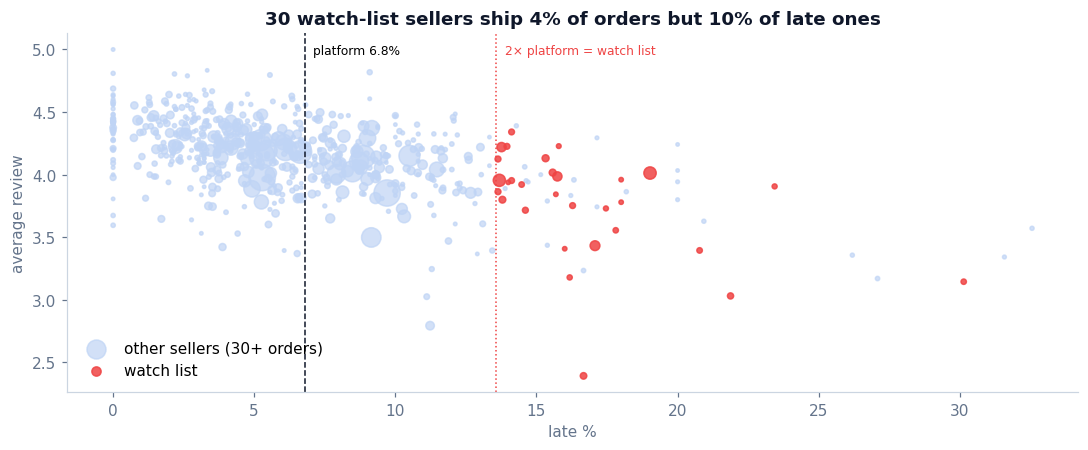

sellers_scored,watch_list_sellers,watch_list_share_of_orders_pct,watch_list_share_of_late_orders_pct
625,30,4.2%,10.2%


seller_id,seller_state,orders,late_orders,late_pct,avg_review,rank_in_state
06a2c3af7b3aee5d69171b0e14f0ee87,MA,389,74,19.0%,4.01,1 of 1
8160255418d5aaa7dbdc9f4c64ebda44,SP,380,52,13.7%,3.95,368 of 405
88460e8ebdecbfecb5f9601833981930,PR,246,42,17.1%,3.43,56 of 57
e5a3438891c0bfdb9394643f95273d8e,SP,216,34,15.7%,3.99,385 of 405
f7ba60f8c3f99e7ee4042fdef03b70c4,SP,218,30,13.8%,4.22,369 of 405
54965bbe3e4f07ae045b90b0b8541f52,PR,73,22,30.1%,3.14,57 of 57
a49928bcdf77c55c6d6e05e09a9b4ca5,SP,96,21,21.9%,3.03,401 of 405
2c9e548be18521d1c43cde1c582c6de8,SP,124,19,15.3%,4.13,380 of 405
cd68562d3f44870c08922d380acae552,SP,122,19,15.6%,4.02,383 of 405
1ca7077d890b907f89be8c954a02686a,SP,108,18,16.7%,2.39,388 of 405


In [8]:
r = run("07 seller scorecard")
sc = con.query("SELECT * FROM seller_scorecard")
fig, ax = plt.subplots(figsize=(10, 4.2))
base = sc[~sc.watch_list.astype(bool)]
watch = sc[sc.watch_list.astype(bool)]
ax.scatter(base.late_rate * 100, base.avg_review, s=base.orders / 6, color=BLUE_L, alpha=0.7, label="other sellers (30+ orders)")
ax.scatter(watch.late_rate * 100, watch.avg_review, s=watch.orders / 6, color=RED, alpha=0.85, label="watch list")
platform = con.query("SELECT 100.0 * AVG(CASE WHEN is_late THEN 1.0 ELSE 0.0 END) AS p FROM fact_orders").p.iloc[0]
ax.axvline(platform, color=INK, ls="--", lw=1)
ax.text(platform + 0.3, 0.97, f"platform {platform:.1f}%", fontsize=8, transform=ax.get_xaxis_transform(), va="top")
ax.axvline(2 * platform, color=RED, ls=":", lw=1)
ax.text(2 * platform + 0.3, 0.97, "2× platform = watch list", fontsize=8, color=RED, transform=ax.get_xaxis_transform(), va="top")
ax.set_xlabel("late %"); ax.set_ylabel("average review"); ax.legend(frameon=False, loc="lower left")
conc = r["watch list concentration"].iloc[0]
ax.set_title(f"{int(conc.watch_list_sellers)} watch-list sellers ship {conc.watch_list_share_of_orders_pct:.0f}% of orders but {conc.watch_list_share_of_late_orders_pct:.0f}% of late ones")
plt.tight_layout(); save(fig, "sql seller scorecard"); plt.show()
display(r["watch list concentration"].style.hide(axis="index").format("{:,.0f}", subset=["sellers_scored", "watch_list_sellers"])
        .format("{:.1f}%", subset=["watch_list_share_of_orders_pct", "watch_list_share_of_late_orders_pct"]))
r["watch list"].style.hide(axis="index").format({"orders": "{:,.0f}", "late_orders": "{:,.0f}", "late_pct": "{:.1f}%", "avg_review": "{:.2f}"})

**Reading the Scorecard**
* 625 sellers have 30+ delivered orders. **30 of them are on the watch list** (50+ orders and late at least twice as often as the platform's 6.8%).
* Together they ship **4.2% of orders but 10.2% of late orders**. Fixing or replacing a short list of sellers removes a tenth of all late deliveries.
* The rank within state (`RANK() OVER (PARTITION BY seller_state ...)`) shows that most of them are near the bottom of their own state, so the problem is the seller, not only the geography. The top case is a seller in Maranhão, late 19% of the time on 389 orders.

## 8 · Summary

| Question | Answer from SQL |
|---|---|
| Do the numbers match the dashboard? | Yes: 96,203 orders, 6.8% late, 4.29★ vs 2.27★, on PostgreSQL and DuckDB. |
| When and where is delivery worst? | Peaks (Nov 2017, Feb–Mar 2018) and the North-East (12.8% late); SP → RJ is the biggest late route. |
| What does a late box cost? | 61% of late orders get 1–2★; late orders are a third of all low reviews. |
| Do customers come back? | Rarely: 3.0% ever reorder, cohorts retain under 1% a month. |
| Who to act on? | 13,744 big spenders at risk (win-back) and 30 watch-list sellers (10% of late orders). |

The tables built here (`fact_orders`, `customer_rfm`, `seller_scorecard`) also feed the **risk model** notebook and the **Streamlit app**.

In [9]:
con.close()